In [1]:
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

In [2]:
X_large, _ = make_blobs(
    n_samples=10000,
    centers=3,
    cluster_std = [1.0, 1.5, 0.8],
    random_state=42
)

large_gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42
)

large_gmm.fit(X_large)

label = large_gmm.predict(X_large)

print("Converged:", large_gmm.converged_)
print("EM iterations:", large_gmm.n_iter_)

Converged: True
EM iterations: 2


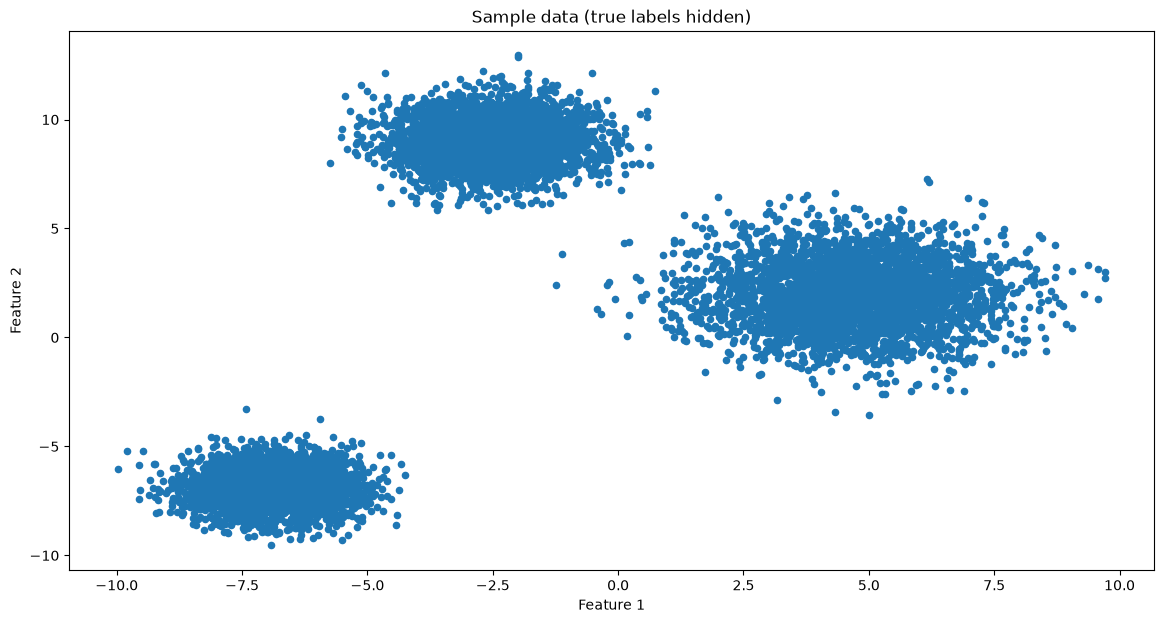

In [3]:
plt.figure(figsize=(14, 7))
plt.scatter(X_large[:,0], X_large[:,1], s=20)
plt.title("Sample data (true labels hidden)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

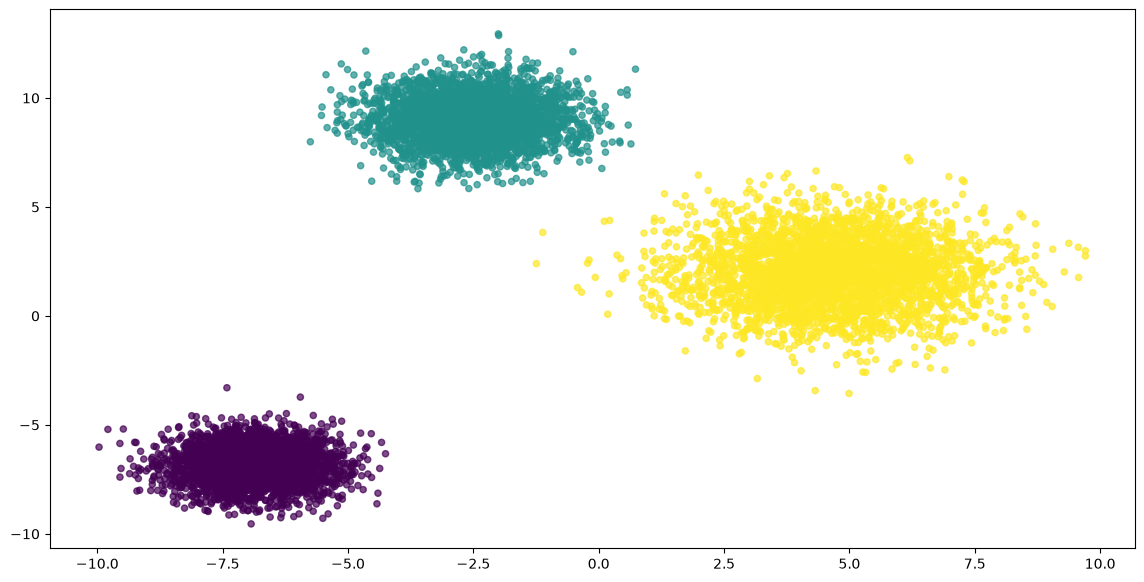

In [4]:
plt.figure(figsize=(14, 7))
plt.scatter(X_large[:,0], X_large[:,1], c=label, cmap="viridis", s=20, alpha=0.7)
plt.show()

In [5]:
membership_probs = large_gmm.predict_proba(X_large)

print("Probability of first 5 components: ")
print(membership_probs[:5].round(3))

print("\nLearned Component weights: ")
print(large_gmm.weights_.round(2))

Probability of first 5 components: 
[[0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]

Learned Component weights: 
[0.33 0.33 0.33]


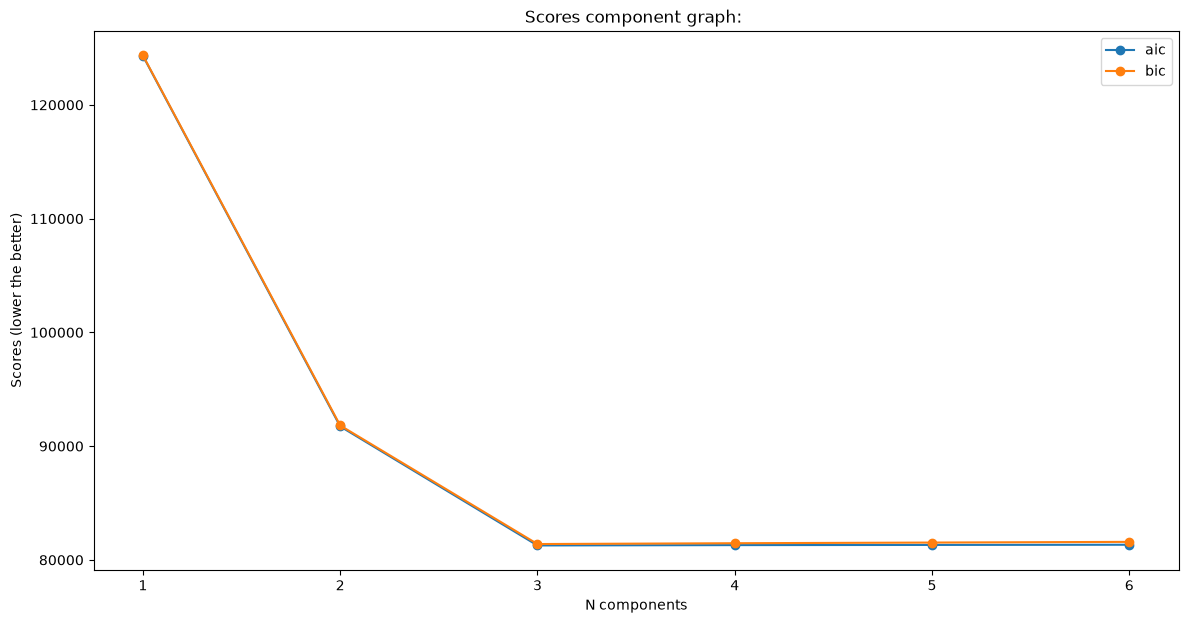

In [6]:
aic_scores = []
bic_scores = []
for n in range(1, 7):
    candidate = GaussianMixture(
        n_components=n,
        covariance_type="full",
        random_state=42
    )

    candidate.fit(X_large)
    aic_score = candidate.aic(X_large)
    bic_score = candidate.bic(X_large)

    aic_scores.append(aic_score)
    bic_scores.append(bic_score)

plt.figure(figsize=(14, 7))
plt.plot(range(1, 7), aic_scores, marker="o", label="aic")
plt.plot(range(1, 7), bic_scores, marker="o", label="bic")
plt.xlabel("N components"); plt.ylabel("Scores (lower the better)")
plt.title("Scores component graph: ")
plt.legend()
plt.show()

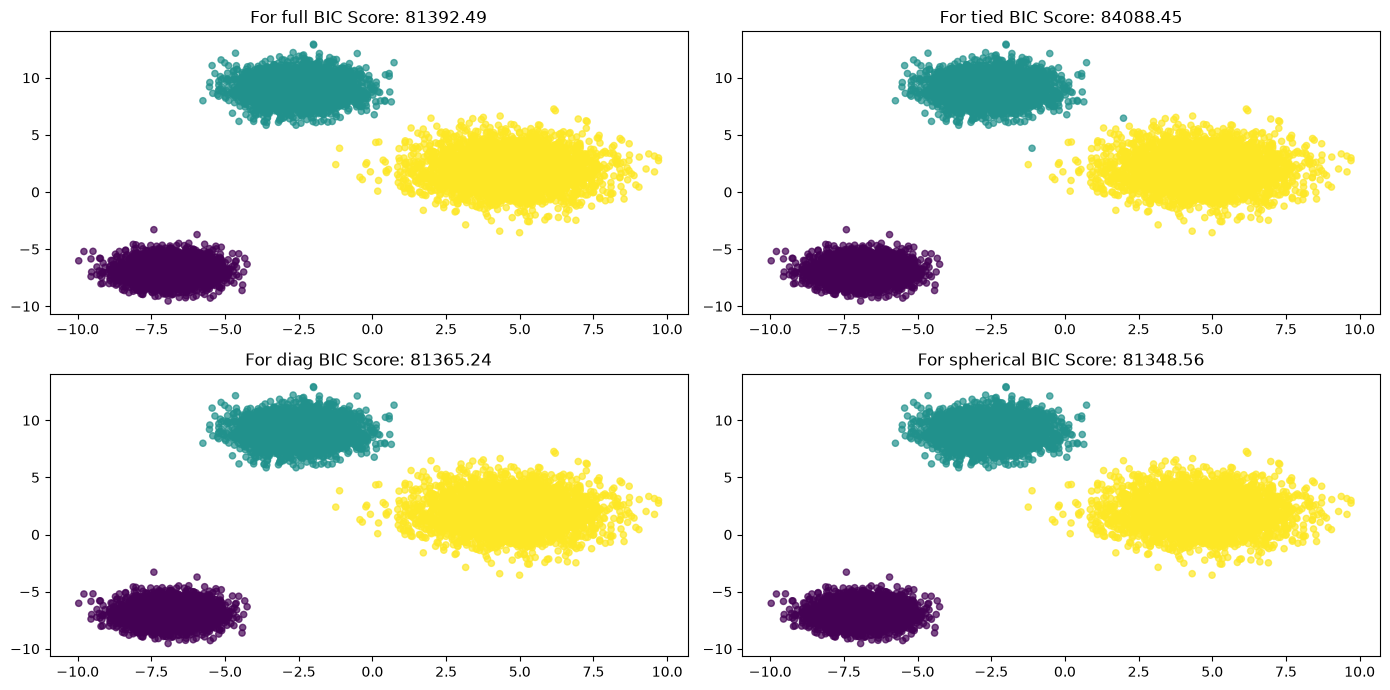

In [7]:
covariances = ["full", "tied", "diag", "spherical"]
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, cov in zip(axes.flatten(), covariances):
    candidate = GaussianMixture(
        n_components=3,
        covariance_type=cov,
        random_state=42
    )

    candidate.fit(X_large)
    c_label = candidate.predict(X_large)
    bic_score = candidate.bic(X_large)
    ax.set_title(f"For {cov} BIC Score: {bic_score:.2f}")
    ax.scatter(X_large[:,0], X_large[:,1], c=c_label, cmap="viridis", s=20, alpha=0.7)

plt.tight_layout()
plt.show()
    

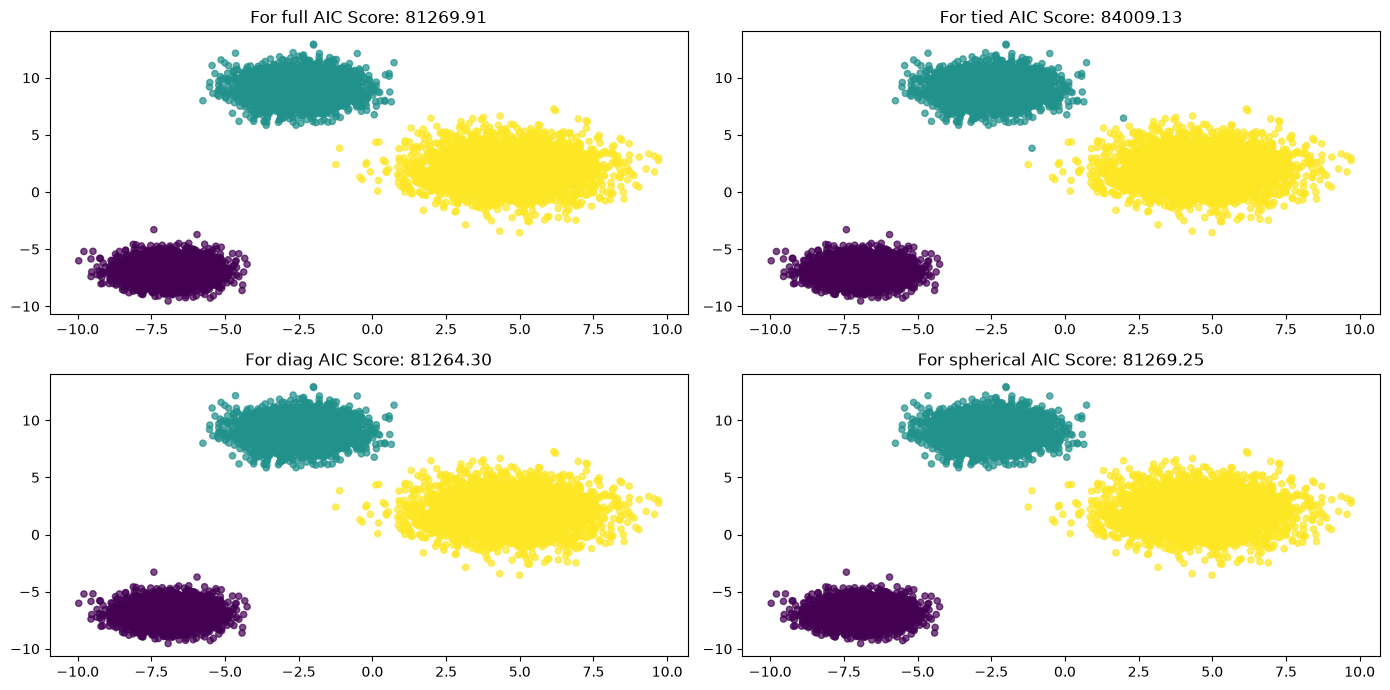

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, cov in zip(axes.flatten(), covariances):
    candidate = GaussianMixture(
        n_components=3,
        covariance_type=cov,
        random_state=42
    )

    candidate.fit(X_large)
    c_label = candidate.predict(X_large)
    aic_score = candidate.aic(X_large)
    ax.set_title(f"For {cov} AIC Score: {aic_score:.2f}")
    ax.scatter(X_large[:,0], X_large[:,1], c=c_label, cmap="viridis", s=20, alpha=0.7)

plt.tight_layout()
plt.show()

In [9]:
results = []

for n in range(1, 7):
    for cov in covariances:
        candidate = GaussianMixture(
            n_components=n,
            covariance_type=cov,
            random_state=42
        )

        candidate.fit(X_large)
        aic_score = candidate.aic(X_large)
        bic_score = candidate.bic(X_large)

        results.append({
            "n_components": n,
            "covariance": cov,
            "AIC_SCORE": aic_score,
            "BIC_SCORE": bic_score
        })

best_aic = min(results, key=lambda row: row["AIC_SCORE"])
best_bic = min(results, key=lambda row: row["BIC_SCORE"])

print("Best by aic: ", best_aic)
print("Best by bic: ", best_bic)

Best by aic:  {'n_components': 3, 'covariance': 'diag', 'AIC_SCORE': 81264.29770574193, 'BIC_SCORE': 81365.2424709496}
Best by bic:  {'n_components': 3, 'covariance': 'spherical', 'AIC_SCORE': 81269.24836967485, 'BIC_SCORE': 81348.56211376659}


In [13]:
best_model = GaussianMixture(
    n_components=3,
    covariance_type="spherical",
    random_state= 42
)

best_model.fit(X_large)

best_label = best_model.predict(X_large)

best_membership_probs = best_model.predict_proba(X_large)

print(f"Probabilities of first 5 components: ")
print(best_membership_probs[:5].round(3))

print(f"\nLearned components weights: ")
print(best_model.weights_.round(2))

print(f"\nConverged: {best_model.converged_}")

print(f"\nEM: {best_model.n_iter_}")

Probabilities of first 5 components: 
[[0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]

Learned components weights: 
[0.33 0.33 0.33]

Converged: True

EM: 2
